# 02 Exploratory analysis

Describes the district-day panel and the incident record before any modelling: seasonality by
hazard, the growth in recorded damaging days with its reporting caveat, the district rate map,
rain against the positive rate, the class balance per split and the completeness of the record.

- **Inputs:** `data/processed/feature-matrix.parquet` and `hydromet-incidents.parquet` (notebook 01),
  `data/processed/district-terrain.csv`, district polygons in `data/raw/`
- **Outputs:** `results/eda-*.csv`; figures `fig-seasonality-by-hazard`, `fig-damaging-days-per-year`,
  `fig-district-rate-map*` and `fig-rain-percentile-vs-rate` in `paper/figures/`
- **Runtime:** about 20 seconds

## Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

from src import config as C
from src import features as Fe
from src import plotting as PL
from src.geography import districts
from src.panel import INCIDENTS_PATH, split_table
from src.regions import belts
from src.weather import load_terrain

PL.setup()
F = pd.read_parquet(C.PROCESSED / "feature-matrix.parquet")
inc = pd.read_parquet(INCIDENTS_PATH)
main = F[F["season"].isin(C.SEASONS)]
print(
    f"feature matrix {F.shape}; modelling rows 2017 to 2025: {len(main):,}; incidents {len(inc):,}"
)

feature matrix (156849, 51); modelling rows 2017 to 2025: 146,223; incidents 16,790


## 1. Class balance per split

The panel's expected counts are asserted in `src/panel.py`; the two rates below must match them.

In [2]:
bal = split_table(F)
bal["seasons"] = [", ".join(map(str, C.SPLITS[s])) for s in bal.index]
for t in ["y_rain", "y_fatal"] + [f"y_{h}" for h in C.HAZARDS.values()]:
    bal[f"{t}_rate"] = (100 * F.groupby("split")[t].mean()).round(2).reindex(bal.index)
bal.to_csv(C.RESULTS / "eda-class-balance.csv")
print(bal.to_string())
assert bal.loc["train", "rate"] == 6.65 and bal.loc["test", "rate"] == 8.46

           rows  positives  rate                             seasons  y_rain_rate  y_fatal_rate  y_flood_rate  y_landslide_rate  y_heavy_rain_rate  y_lightning_rate
split                                                                                                                                                               
train     97482       6482  6.65  2017, 2018, 2019, 2020, 2021, 2022         4.26          2.74          0.96              2.22               1.60              2.50
validate  16247        722  4.44                                2023         2.57          1.45          0.39              1.33               0.97              1.91
test      32494       2749  8.46                          2024, 2025         5.49          2.78          1.44              2.55               2.23              3.24
check     10626        614  5.78                                2026         3.39          2.08          0.87              1.60               1.09              2.48


## 2. Seasonality by hazard

Share of district-days with a damaging incident of each hazard, by month, 2017 to 2025. Lightning
peaks in the pre-monsoon (April and May); the rain-driven hazards peak in July and August.

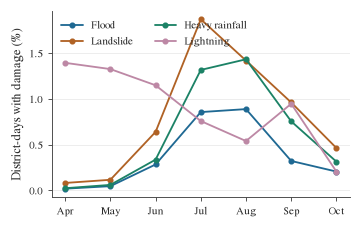

       flood  landslide  heavy_rain  lightning
month                                         
4       0.02       0.08        0.02       1.39
5       0.05       0.12        0.06       1.33
6       0.28       0.64        0.34       1.15
7       0.86       1.87        1.32       0.76
8       0.89       1.42        1.43       0.54
9       0.32       0.96        0.76       0.95
10      0.21       0.46        0.31       0.21


In [3]:
HAZ = list(C.HAZARDS.values())
seas = main.groupby("month")[[f"day_{h}" for h in HAZ]].mean() * 100
seas.columns = HAZ
seas.to_csv(C.RESULTS / "eda-seasonality-by-hazard.csv")
f, ax = PL.fig(height=2.2)
for h in HAZ:
    ax.plot(seas.index, seas[h], marker="o", ms=3, color=PL.HAZARD_COL[h], label=PL.HAZARD_NAME[h])
ax.set_xticks(range(4, 11))
ax.set_xticklabels(["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"])
ax.set_ylabel("District-days with damage (%)")
ax.legend(ncol=2, loc="upper left")
PL.save(f, "fig-seasonality-by-hazard")
print(seas.round(2).to_string())

## 3. Damaging days per year and the reporting caveat

District-days with any recorded incident of the four hazards grew far faster than district-days
with a damaging one. Reporting of minor incidents expanded after BIPAD went live and after the
2020 change to prompt entry; the damaging label is the more stable of the two.

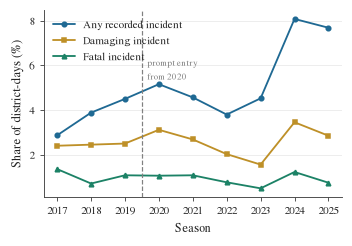

        any_rate  damaging_rate  fatal_rate  positives   rows  y_rate
season                                                               
2017        2.87           2.40        1.35        960  16247    5.91
2018        3.88           2.45        0.71       1106  16247    6.81
2019        4.50           2.50        1.08       1062  16247    6.54
2020        5.16           3.11        1.06       1329  16247    8.18
2021        4.57           2.68        1.08       1146  16247    7.05
2022        3.80           2.02        0.76        879  16247    5.41
2023        4.52           1.56        0.49        722  16247    4.44
2024        8.08           3.45        1.22       1466  16247    9.02
2025        7.69           2.85        0.74       1283  16247    7.90
growth 2017 to 2024: any x2.8, damaging x1.4


In [4]:
yr = main.groupby("season").agg(
    any_rate=("day_any", "mean"),
    damaging_rate=("day_damaging", "mean"),
    fatal_rate=("day_fatal", "mean"),
    positives=("y", "sum"),
    rows=("y", "size"),
)
yr["y_rate"] = yr["positives"] / yr["rows"]
yr[["any_rate", "damaging_rate", "fatal_rate", "y_rate"]] *= 100
yr.round(3).to_csv(C.RESULTS / "eda-rates-per-year.csv")
f, ax = PL.fig(height=2.2)
ax.plot(yr.index, yr["any_rate"], marker="o", ms=3, label="Any recorded incident")
ax.plot(yr.index, yr["damaging_rate"], marker="s", ms=3, label="Damaging incident")
ax.plot(yr.index, yr["fatal_rate"], marker="^", ms=3, label="Fatal incident")
ax.axvline(2019.5, color="grey", lw=0.8, ls="--")
ax.text(2019.65, 6.4, "prompt entry\nfrom 2020", fontsize=6, color="grey", va="top")
ax.set_ylabel("Share of district-days (%)")
ax.set_xlabel("Season")
ax.legend(loc="upper left")
PL.save(f, "fig-damaging-days-per-year")
print(yr.round(2).to_string())
print(
    f"growth 2017 to 2024: any x{yr.loc[2024, 'any_rate'] / yr.loc[2017, 'any_rate']:.1f}, damaging x{yr.loc[2024, 'damaging_rate'] / yr.loc[2017, 'damaging_rate']:.1f}"
)

## 4. District map of damaging-day rates

District polygons are the OCHA COD-AB boundaries (HDX, CC BY-IGO, simplified to about 150 m).
Panel (a): share of issue days with a damaging incident in the next three days, 2017 to 2025.
Panel (b): the ecological belt proxy derived from ward elevations (see `regions.belts`).

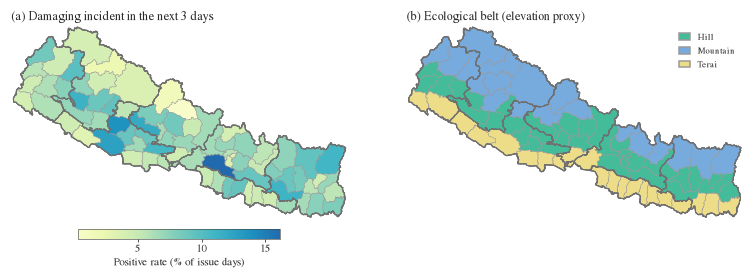

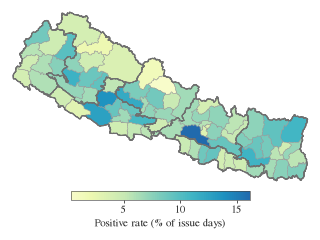

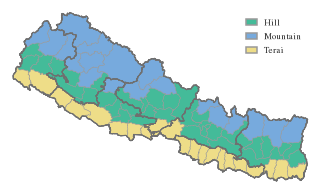

top 8 districts by positive rate (%): {'Makwanpur': 16.2, 'Rolpa': 13.8, 'Dang': 12.7, 'Baglung': 12.0, 'Dailekh': 11.3, 'Udayapur': 11.1, 'Taplejung': 10.9, 'Palpa': 10.7}
positive rate by belt (%): {'Hill': 7.67, 'Mountain': 5.97, 'Terai': 6.05}
districts per belt: {'Hill': 37, 'Terai': 21, 'Mountain': 19}


In [5]:
D = districts().set_index("district")
T = load_terrain().set_index("district")
rate = main.groupby("district")["y"].mean() * 100
belt = belts(T)
geo = D.join(rate.rename("y_rate")).join(T).join(belt.rename("belt"))
geo.to_csv(C.RESULTS / "eda-district-rates.csv")
f, axes = PL.fig(width=PL.PAGE_W, height=2.3, ncols=2)
f.subplots_adjust(wspace=0.05, left=0.01, right=0.99)
PL.choropleth(
    axes[0],
    geo["y_rate"],
    "Positive rate (% of issue days)",
    title="(a) Damaging incident in the next 3 days",
)
PL.categorical_map(axes[1], geo["belt"], PL.BELT_COL, title="(b) Ecological belt (elevation proxy)")
PL.save(f, "fig-district-rate-map")
# Single-panel versions: (a) in the paper body at column width, (b) in the appendix.
f, ax = PL.fig(width=PL.COL_W, height=2.2)
PL.choropleth(ax, geo["y_rate"], "Positive rate (% of issue days)")
PL.save(f, "fig-district-rate-map-a")
f, ax = PL.fig(width=PL.COL_W, height=2.2)
PL.categorical_map(ax, geo["belt"], PL.BELT_COL)
PL.save(f, "fig-district-rate-map-b")
print(
    "top 8 districts by positive rate (%):",
    rate.sort_values(ascending=False).head(8).round(1).to_dict(),
)
print(
    "positive rate by belt (%):",
    main.merge(belt.rename("belt"), left_on="district", right_index=True)
    .groupby("belt")["y"]
    .mean()
    .mul(100)
    .round(2)
    .to_dict(),
)
print("districts per belt:", belt.value_counts().to_dict())

## 5. Rain percentile against the positive rate

The percentile of the 3-day ERA5 rain sum within the district's 2017 to 2022 distribution, in 20
bins, against the share of positive rows, for the pooled target and the rain-driven target
(no lightning). Training and test seasons are drawn separately: the shape is stable.

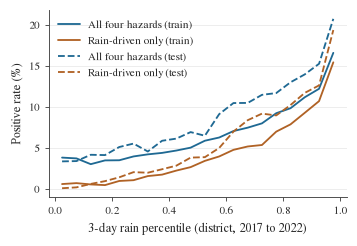

positive rate (%) by rain decile: [3.3, 3.3, 3.7, 4.3, 5.0, 6.2, 7.8, 9.0, 10.7, 14.7]


In [6]:
f, ax = PL.fig(height=2.2)
for split, ls in (("train", "-"), ("test", "--")):
    d = F[F["split"] == split]
    b = pd.cut(d["rain_3d_pct"], np.linspace(0, 1, 21), include_lowest=True)
    g = d.groupby(b, observed=True)[["y", "y_rain"]].mean() * 100
    x = [iv.mid for iv in g.index]
    ax.plot(x, g["y"], ls=ls, color=PL.OKABE_MUTED[0], label=f"All four hazards ({split})")
    ax.plot(x, g["y_rain"], ls=ls, color=PL.OKABE_MUTED[3], label=f"Rain-driven only ({split})")
ax.set_xlabel("3-day rain percentile (district, 2017 to 2022)")
ax.set_ylabel("Positive rate (%)")
ax.legend(loc="upper left")
PL.save(f, "fig-rain-percentile-vs-rate")
dec = pd.qcut(main["rain_3d_pct"], 10, labels=False)
print("positive rate (%) by rain decile:", (main.groupby(dec)["y"].mean() * 100).round(1).tolist())

## 6. Record completeness and entry lag

Incidents of the four hazards per year, the share that are damaging, and how quickly they were
entered. Before 2020 the entry date is bulk entry years later (so the recent-incident features use
synthetic lags drawn from 2020 to 2025, see `features.harmonise_entry_lags`).

In [7]:
inc["year"] = inc["date"].dt.year
inc["lag_days"] = Fe.entry_lag_days(inc)
comp = (
    inc[inc["year"].between(2017, 2026)]
    .groupby("year")
    .agg(
        incidents=("id", "size"),
        damaging=("damaging", "sum"),
        fatal=("fatal", "sum"),
        median_lag_days=("lag_days", "median"),
        share_entered_within_3d=("lag_days", lambda s: (s <= 3).mean()),
    )
)
comp["share_damaging"] = comp["damaging"] / comp["incidents"]
comp.round(3).to_csv(C.RESULTS / "eda-record-completeness.csv")
print(comp.round(3).to_string())
hz = inc[inc["year"].between(2017, 2025) & inc["damaging"]].groupby("hazard").size()
print("damaging incidents 2017 to 2025 by hazard:", hz.to_dict())
pos = main[main["y"] == 1]
print(
    f"share of positives with a lightning label: {pos['y_lightning'].mean():.3f}; lightning only: {(pos['y_lightning'].eq(1) & pos['y_rain'].eq(0)).mean():.3f}"
)

      incidents  damaging  fatal  median_lag_days  share_entered_within_3d  share_damaging
year                                                                                      
2017        782       587    305            930.0                    0.000           0.751
2018        891       505    139            584.0                    0.000           0.567
2019       1141       635    230            231.0                    0.000           0.557
2020       1254       720    211              1.0                    0.964           0.574
2021       1056       585    225              1.0                    0.932           0.554
2022        815       410    147              1.0                    0.982           0.503
2023       1088       319     89              1.0                    0.978           0.293
2024       2366       877    324              1.0                    0.955           0.371
2025       1795       565    144              1.0                    0.972           0.315

## 7. Weather summary

ERA5 at the 77 district centroids: no gaps. Daily rain is heavier in the Terai and the middle
hills than at the high-mountain grid points, which is the known orographic under-estimate.

In [8]:
wx = main.groupby("district")[["rain_1d", "tmax_1d"]].mean().join(belt.rename("belt"))
print(wx.groupby("belt")[["rain_1d", "tmax_1d"]].mean().round(2))
print("rows with any NaN in feature set B:", int(main[Fe.FEATURES_B].isna().any(axis=1).sum()))

          rain_1d  tmax_1d
belt                      
Hill        11.76    25.42
Mountain     9.59    15.67
Terai        7.51    33.28
rows with any NaN in feature set B: 0
